# Introduction

The **STEW (Simultaneous Task EEG Workload) dataset** contains electroencephalography (EEG) recordings from 48 participants under resting and multitasking conditions. The signals were recorded using a 14-channel EEG headset at a sampling rate of 128 Hz, with the aim of studying mental workload.

The objective of this project is to compare different machine learning approaches for classifying mental workload (high or low) using the STEW dataset. In particular, we investigate the impact of two dimensionality reduction and feature selection techniques, **Principal Component Analysis (PCA)** and **ANOVA-based feature selection**, combined with different classification models studied in our course. By evaluating their performance using appropriate classification metrics, we aim to identify which combinations achieve the best results.

Article presenting the dataset, with the acquisition methods and a data analysis: [Lim et al, 2018](https://pubmed.ncbi.nlm.nih.gov/30281467/)

Original Dataset (in EDF format) from: [STEW: Simultaneous Tast EEG Dataset](https://ieee-dataport.org/open-access/stew-simultaneous-task-eeg-workload-dataset)

## Project Workflow

The first stage of this project consists of data preprocessing and feature extraction. Each EEG sample contains recordings from 14 channels over 2 seconds, sampled at 128 Hz, resulting in 256 data points per channel and a total of 3,584 raw features per sample ($14 \times 2 \times 128$).

To reduce the dimensionality of the data while preserving relevant information, we extract 15 features from each EEG channel, resulting in a total of 210 features per sample ($14 \times 15$). These features describe the signals in both the time and frequency domains. They include statistical measures such as the mean, standard deviation, variance, root mean square (RMS), skewness, and kurtosis, as well as frequency-band power, relative power in the delta, theta, alpha, beta, and gamma bands, and spectral entropy.

This feature extraction step transforms the raw EEG signals into a more compact and informative representation, which will then be used to compare PCA and ANOVA-based feature selection in combination with different machine learning classifiers.

The second stage focuses on building machine learning pipelines for the different combinations of feature selection or dimensionality reduction techniques and classification models. For each model, we define a set of hyperparameters to explore in order to identify the most effective configurations.

We then split the dataset into training and testing sets, using a StratifiedGroupKFold strategy to preserve class proportions while accounting for participant groups. This helps prevent data leakage between training and validation folds. Next, we perform GridSearchCV to systematically evaluate the different hyperparameter combinations through cross-validation and select the best-performing configuration for each pipeline.

Once the grid search is complete, we present the results in a table summarizing the main performance metrics for each model and configuration. We also generate visualizations, including model performance comparisons, standard deviation plots to assess the variability of cross-validation scores, and confusion matrices to examine classification errors in greater detail.

Finally, we conduct an in-depth analysis of the results to compare the different approaches, assess the impact of PCA and ANOVA-based feature selection on classification performance, and identify which combinations of techniques and models provide the most reliable results.

# Project

In [3]:
import os

from huggingface_hub import hf_hub_download

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import welch
from scipy.stats import skew, kurtosis

from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

## Preprocessing
### Data Loading

Preprocessed dataset from: [monster-monash/STEW](https://huggingface.co/datasets/monster-monash/STEW)

In [2]:
REPO_ID = "monster-monash/STEW"

def download_file(filename):
    return hf_hub_download(repo_id=REPO_ID,filename=filename,repo_type="dataset")

X_path = download_file("STEW_X.npy")

Y_path = download_file("STEW_y.csv")

SUBJECT_ID_path = download_file("STEW_subject_id.csv")

X = np.load(X_path)
Y = pd.read_csv(Y_path, header= None).squeeze().to_numpy()
SUBJECT_ID = pd.read_csv(SUBJECT_ID_path, header=None).squeeze().to_numpy()

### Data Exploration

In [3]:
# We verify the shapes of the three arrays

assert(X.ndim == 3)
assert(X.shape == (28512,14,256)) # Expected shape from the tabular dataset description
assert(len(X)==len(Y)==len(SUBJECT_ID))

## Feature engineering

We crete a .csv table with the chosen features:

In [4]:
EEG_CHANNELS = ["AF3", "F7", "F3", "FC5", "T7", "P7", "O1", "O2", "P8", "T8", "FC6", "F4", "F8", "AF4"]
SAMPLING_FREQUENCY = 128

In [5]:
def extract_features(signal):

    # Time-domain features
    new_features = {
        "mean": np.mean(signal),
        "std" : np.std(signal),
        "var" : np.var(signal),
        "rms" : np.sqrt(np.mean(signal**2)),
        "skewness": skew(signal, bias=True),
        "kurtosis": kurtosis(signal, fisher=True, bias=True),
    }

    # Frequency-domain features
    freqs, psd = welch(
        signal,
        fs=SAMPLING_FREQUENCY,
        nperseg=len(signal)
    )

    frequency_resolution = freqs[1] - freqs[0] 

    FREQUENCY_BANDS = {
        "delta": (1, 4),
        "theta": (4, 8),
        "alpha": (8, 12),
        "beta": (12, 30),
        "gamma": (30, 50),
    }

    total_mask = (freqs >= 1) & (freqs < 45)
    total_power = np.sum(psd[total_mask]) * frequency_resolution

    for band, (low, high) in FREQUENCY_BANDS.items():

        mask = (freqs >= low) & (freqs < high)

        power = (
            np.sum(psd[mask]) * frequency_resolution
            if np.any(mask) else 0.0
        )

        new_features[f"{band}_power"] = power

        new_features[f"{band}_relative_power"] = (
            power / total_power
            if total_power > 1e-12 else 0.0
        )

    # Spectral entropy over the 1–45 Hz range
    psd_band = psd[total_mask]
    power_sum = psd_band.sum()

    if power_sum > 1e-12:
        probabilities = psd_band / power_sum
        probabilities = probabilities[probabilities > 0]

        new_features["spectral_entropy"] = -np.sum(
            probabilities * np.log2(probabilities)
        )
    else:
        new_features["spectral_entropy"] = 0.0

    return new_features

In [6]:
records = []

for sample_idx in range(len(X)):

    eeg_sample = X[sample_idx]

    record = {
        "sample_id": sample_idx,
        "subject_id": SUBJECT_ID[sample_idx],
    }

    for channel_idx, channel_name in enumerate(EEG_CHANNELS):

        signal = eeg_sample[channel_idx, :]

        channel_features = extract_features(signal)

        for feature_name, value in channel_features.items():
            column_name = f"{channel_name}_{feature_name}"
            record[column_name] = value

    record["label"] = Y[sample_idx]
    records.append(record)

    if (sample_idx + 1) % 1000 == 0:
        print(f"Processed {sample_idx + 1}/{len(X)} examples")

print(f"Processed {sample_idx + 1}/{len(X)} examples")

Processed 1000/28512 examples
Processed 2000/28512 examples
Processed 3000/28512 examples
Processed 4000/28512 examples
Processed 5000/28512 examples
Processed 6000/28512 examples
Processed 7000/28512 examples
Processed 8000/28512 examples
Processed 9000/28512 examples
Processed 10000/28512 examples
Processed 11000/28512 examples
Processed 12000/28512 examples
Processed 13000/28512 examples
Processed 14000/28512 examples
Processed 15000/28512 examples
Processed 16000/28512 examples
Processed 17000/28512 examples
Processed 18000/28512 examples
Processed 19000/28512 examples
Processed 20000/28512 examples
Processed 21000/28512 examples
Processed 22000/28512 examples
Processed 23000/28512 examples
Processed 24000/28512 examples
Processed 25000/28512 examples
Processed 26000/28512 examples
Processed 27000/28512 examples
Processed 28000/28512 examples
Processed 28512/28512 examples


We create a dataframe with the extracted outputs and write it to a .csv file

In [7]:
DATASET_PATH = "STEW_features.csv"

extracted_features = pd.DataFrame(records)
print(extracted_features.head())
print(extracted_features.shape)

extracted_features.to_csv(DATASET_PATH,index=False)

   sample_id  subject_id  AF3_mean    AF3_std     AF3_var    AF3_rms  \
0          0          12 -2.364527  16.718996  279.524841  16.885374   
1          1          12  1.513650  15.534682  241.326355  15.608251   
2          2          12  0.492984  14.909048  222.279709  14.917197   
3          3          12 -2.007783  14.349675  205.913177  14.489458   
4          4          12  1.876135  13.039218  170.021210  13.173500   

   AF3_skewness  AF3_kurtosis  AF3_delta_power  AF3_delta_relative_power  ...  \
0     -0.339354     -0.337851       114.806351                  0.573799  ...   
1     -0.468445     -0.308483       185.131073                  0.716253  ...   
2     -0.283593     -0.254668       141.955475                  0.627093  ...   
3     -0.157667     -0.236524        81.054817                  0.508537  ...   
4     -0.063752     -0.338315        59.304790                  0.397247  ...   

   AF4_theta_power  AF4_theta_relative_power  AF4_alpha_power  \
0       323.099

## Pipelines: Features reduction and Model training

We want to analyze the impact of PCA and ANOVA on different SVM models like RBF and Logistic Regression as a guideline.

### Hyperparameters

In [1]:
# Fixed seed so that all results are reproducible
RANDOM_STATE = 42

# Feature subset sizes to compare (the smallest ones go to the quantum SVM)
CANDIDATE_KS = [5, 10, 20, 50, 100]

# Main metric used to compare the methods
SCORING = 'f1_weighted'

### Train Test Split

In [9]:
# Separate features, target and subject ids.
# subject_id is NOT a feature, but we keep it as `groups` so that the
# cross-validation never puts the same person in both train and test.
X = extracted_features.drop(columns=['sample_id', 'subject_id', 'label'])
y = extracted_features['label']
groups = extracted_features['subject_id']

# Make sure the data is clean before any modelling
assert X.isna().sum().sum() == 0, "NaN values found in features"
assert all(np.issubdtype(t, np.number) for t in X.dtypes), "Non-numeric columns found"

# Grouped, stratified CV: no subject appears in both train and validation folds.
# The same object is used for both methods, so they see identical splits.
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

### Pipelines

In [10]:
# All reducers
reducers = {
    "ANOVA": (
        SelectKBest(score_func=f_classif),
        {"reducer__k": CANDIDATE_KS},
    ),
    "PCA": (
        PCA(),
        {"reducer__n_components": CANDIDATE_KS},
    ),
}

In [4]:
# All classifiers
classifiers = {
    "SVM": (
        SVC(),
        {
            "classifier__kernel": ["rbf"],
            "classifier__C": [0.1, 1, 10, 100],
            #"classifier__gamma": ["scale", 0.01, 0.1, 1],
        },
    ),
    "Logistic Regression": (
        LogisticRegression(max_iter=2000),
        {
            "classifier__C": [0.1, 1, 10, 100],
        },
    ),
}

In [13]:
searches = {}
results = []

for reducer_name, (reducer, reducer_grid) in reducers.items():
    for classifier_name, (classifier, classifier_grid) in classifiers.items():
        name = f"{reducer_name} + {classifier_name}"

        pipeline = Pipeline([
            ("scaler", StandardScaler()),
            ("reducer", reducer),
            ("classifier", classifier),
        ])

        param_grid = {
            **reducer_grid,
            **classifier_grid,
        }

        print(f"\nExecuting GridSearchCV: {name}")

        search = GridSearchCV(
            estimator=pipeline,
            param_grid=param_grid,
            cv=cv,
            scoring=SCORING,
            n_jobs=-1,
            verbose=1,
        )

        search.fit(X, y, groups=groups)

        searches[name] = search

        results.append({
            "Model": name,
            "Best CV F1-weighted": search.best_score_,
            "Best parameters": search.best_params_,
        })

        print(f"- Best score: {search.best_score_:.4f}")
        print(f"- Best parameters: {search.best_params_}")


Executing GridSearchCV: ANOVA + SVM
Fitting 5 folds for each of 20 candidates, totalling 100 fits
- Best score: 0.7471
- Best parameters: {'classifier__C': 1, 'classifier__kernel': 'rbf', 'reducer__k': 50}

Executing GridSearchCV: ANOVA + Logistic Regression
Fitting 5 folds for each of 20 candidates, totalling 100 fits
- Best score: 0.7256
- Best parameters: {'classifier__C': 10, 'reducer__k': 100}

Executing GridSearchCV: PCA + SVM
Fitting 5 folds for each of 20 candidates, totalling 100 fits
- Best score: 0.7348
- Best parameters: {'classifier__C': 1, 'classifier__kernel': 'rbf', 'reducer__n_components': 100}

Executing GridSearchCV: PCA + Logistic Regression
Fitting 5 folds for each of 20 candidates, totalling 100 fits
- Best score: 0.7282
- Best parameters: {'classifier__C': 10, 'reducer__n_components': 100}


### Scoring

In [14]:
comparison_results = []

for name, search in searches.items():

    cv_results = pd.DataFrame(search.cv_results_)

    # Identify the dimensionality parameter:
    # ANOVA uses reducer__k, PCA uses reducer__n_components.
    dim_param = (
        "param_reducer__k"
        if "param_reducer__k" in cv_results.columns
        else "param_reducer__n_components"
    )

    # For each dimensionality, keep the best classifier hyperparameters.
    best_by_dim = (
        cv_results.loc[
            cv_results.groupby(dim_param)["mean_test_score"].idxmax()
        ]
        .sort_values(dim_param)
    )

    for _, row in best_by_dim.iterrows():
        comparison_results.append({
            "Model": name,
            "k": int(row[dim_param]),
            "F1_mean": row["mean_test_score"],
            "F1_std": row["std_test_score"],
            "Best_params": row["params"],
        })

# Detailed results: one row per model and dimensionality.
results_df = (
    pd.DataFrame(comparison_results)
    .sort_values(["Model", "k"])
    .reset_index(drop=True)
)

# Save detailed results for reuse in the merged notebook.
results_df.to_csv("all_models_f1_by_dimension.csv", index=False)

# Summary: best overall CV score for each of the six pipelines.
best_results_df = (
    results_df.loc[results_df.groupby("Model")["F1_mean"].idxmax()]
    .sort_values("F1_mean", ascending=False)
    .reset_index(drop=True)
)

best_results_df.to_csv("best_results_by_model.csv", index=False)

# Display both tables in JupyterLab.
display(results_df)
display(best_results_df)

,Model,k,F1_mean,F1_std,Best_params
0,ANOVA + Logistic Regression,5,0.635026,0.022085,"{'classifier__C': 1, 'reducer__k': 5}"
1,ANOVA + Logistic Regression,10,0.671060,0.020469,"{'classifier__C': 0.1, 'reducer__k': 10}"
2,ANOVA + Logistic Regression,20,0.688482,0.040150,"{'classifier__C': 100, 'reducer__k': 20}"
3,ANOVA + Logistic Regression,50,0.719321,0.056838,"{'classifier__C': 0.1, 'reducer__k': 50}"
4,ANOVA + Logistic Regression,100,0.725595,0.055757,"{'classifier__C': 10, 'reducer__k': 100}"
5,ANOVA + SVM,5,0.648916,0.019028,"{'classifier__C': 10, 'classifier__kernel': 'r..."
6,ANOVA + SVM,10,0.691149,0.020853,"{'classifier__C': 1, 'classifier__kernel': 'rb..."
7,ANOVA + SVM,20,0.703304,0.034461,"{'classifier__C': 1, 'classifier__kernel': 'rb..."
8,ANOVA + SVM,50,0.747133,0.042214,"{'classifier__C': 1, 'classifier__kernel': 'rb..."
9,ANOVA + SVM,100,0.745820,0.043268,"{'classifier__C': 1, 'classifier__kernel': 'rb..."


,Model,k,F1_mean,F1_std,Best_params
0,ANOVA + SVM,50,0.747133,0.042214,"{'classifier__C': 1, 'classifier__kernel': 'rb..."
1,PCA + SVM,100,0.734829,0.046595,"{'classifier__C': 1, 'classifier__kernel': 'rb..."
2,PCA + Logistic Regression,100,0.728227,0.032351,"{'classifier__C': 10, 'reducer__n_components':..."
3,ANOVA + Logistic Regression,100,0.725595,0.055757,"{'classifier__C': 10, 'reducer__k': 100}"


### Plotting

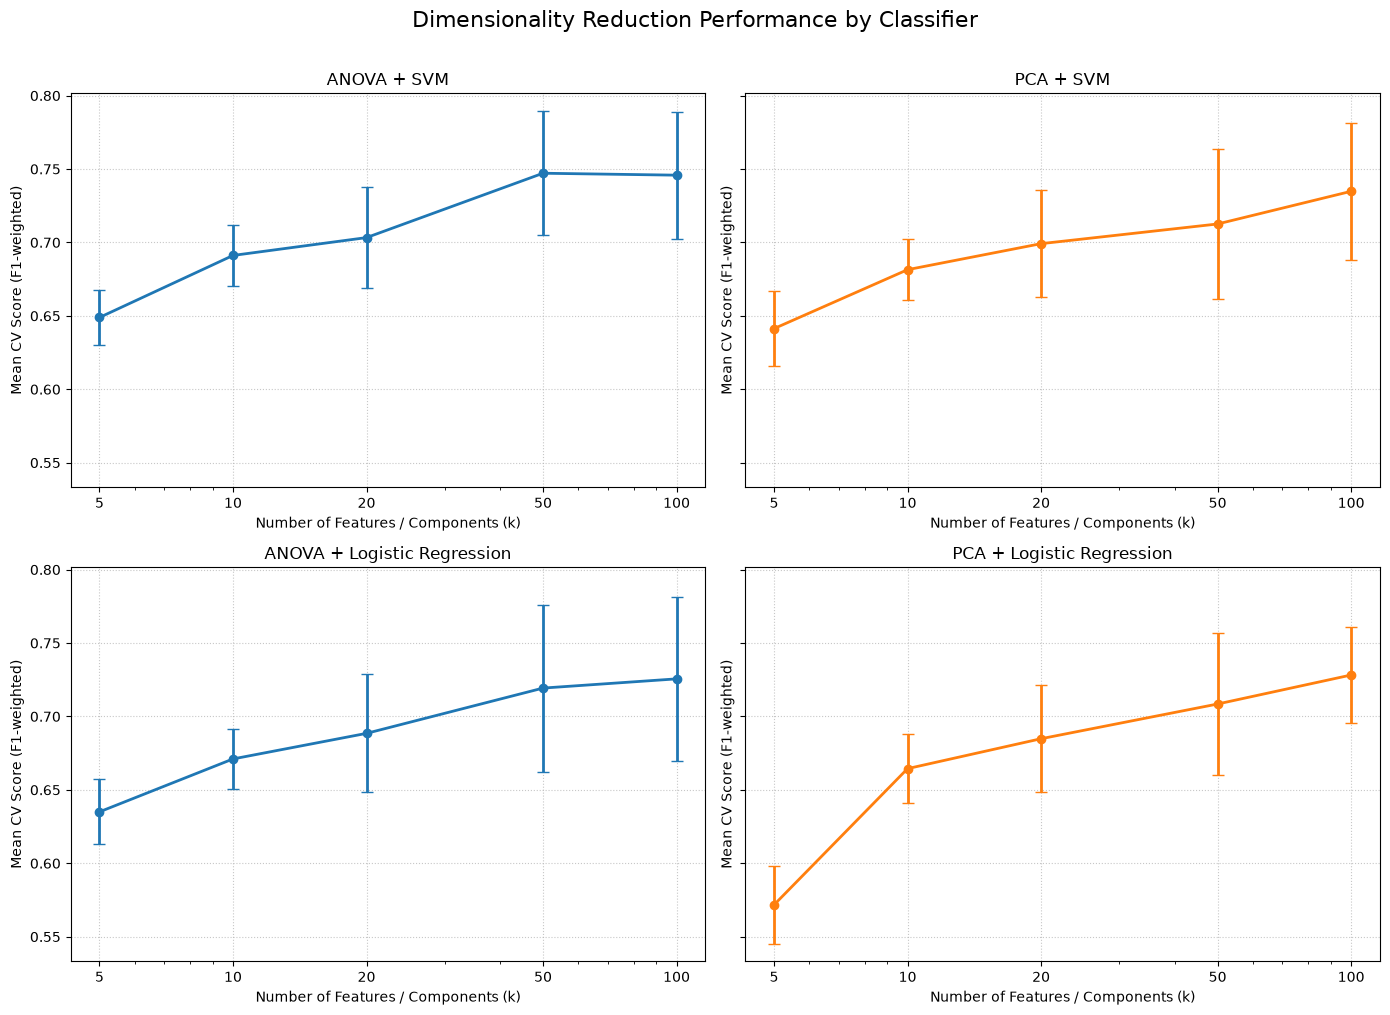

In [15]:
classifier_names = list(classifiers.keys())
reducer_names = list(reducers.keys())

n_rows = len(classifier_names)
n_cols = len(reducer_names)

# Generate one color per reducer.
cmap = plt.get_cmap("tab10")
colors = {
    name: cmap(i % cmap.N)
    for i, name in enumerate(reducer_names)
}

fig, axes = plt.subplots(
    nrows=n_rows,
    ncols=n_cols,
    figsize=(7 * n_cols, 5 * n_rows),
    sharey=True,
    squeeze=False
)

for row, classifier_name in enumerate(classifier_names):

    for col, reducer_name in enumerate(reducer_names):

        ax = axes[row, col]
        model_name = f"{reducer_name} + {classifier_name}"

        model_results = (
            results_df[results_df["Model"] == model_name]
            .sort_values("k")
        )

        if model_results.empty:
            ax.set_title(f"{reducer_name} + {classifier_name} (no results)")
            continue

        ax.errorbar(
            model_results["k"],
            model_results["F1_mean"],
            yerr=model_results["F1_std"],
            marker="o",
            color=colors[reducer_name],
            linewidth=2,
            capsize=4
        )

        ax.set_xscale("log")
        ax.set_xticks(model_results["k"])
        ax.set_xticklabels(model_results["k"])

        ax.set_title(f"{reducer_name} + {classifier_name}")
        ax.set_xlabel("Number of Features / Components (k)")
        ax.set_ylabel("Mean CV Score (F1-weighted)")
        ax.grid(True, linestyle=":", alpha=0.7)

fig.suptitle(
    "Dimensionality Reduction Performance by Classifier",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.savefig(
    "reduction_comparison_by_classifier.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

### Analysis